In [2]:
import torch

# Define device explicitly
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------------------------------------------------------
# VGG-16 Configuration (Configuration D in Simonyan & Zisserman, 2014)
# Numbers represent output channels for 3x3 Conv layers; 'M' represents MaxPool2d.
# Total: 13 Convolutional layers + 3 Fully Connected layers = 16 layers.
# ---------------------------------------------------------
VGG16_CONFIG = [
    64, 64, 'M',          # Block 1 (2 convs)
    128, 128, 'M',        # Block 2 (2 convs)
    256, 256, 256, 'M',   # Block 3 (3 convs)
    512, 512, 512, 'M',   # Block 4 (3 convs)
    512, 512, 512, 'M'    # Block 5 (3 convs)
]

class VGG16FromScratch(nn.Module):
    """
    VGG-16 implementation built completely from scratch.
    Adapted with an adaptive average pooling layer to seamlessly support both 
    standard ImageNet (224x224) and smaller spatial resolutions (28x28 / 32x32).
    """
    def __init__(self, in_channels: int = 3, num_classes: int = 10):
        super(VGG16FromScratch, self).__init__()
        
        self.in_channels = in_channels
        self.features = self._make_layers(VGG16_CONFIG)
        
        # Adaptive pooling ensures a fixed (1x1) spatial output before classification
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        
        # Classic 3-layer MLP classifier head
        self.classifier = nn.Sequential(
            nn.Linear(512 * 1 * 1, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes)
        )
        
    def _make_layers(self, cfg: list) -> nn.Sequential:
        layers = []
        in_c = self.in_channels
        for x in cfg:
            if x == 'M':
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                layers.append(nn.Conv2d(in_c, x, kernel_size=3, padding=1))
                layers.append(nn.BatchNorm2d(x)) # Batch normalization accelerates SGD convergence
                layers.append(nn.ReLU(inplace=True))
                in_c = x
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)

# ---------------------------------------------------------
# Sanity Check for VGG16
# ---------------------------------------------------------
if __name__ == "__main__":
    vgg_test = VGG16FromScratch(in_channels=3, num_classes=10).to(device)
    dummy_input = torch.randn(2, 3, 32, 32).to(device)
    dummy_out = vgg_test(dummy_input)
    print("VGG-16 from scratch successfully instantiated!")
    print(f"Output shape for batch size 2: {dummy_out.shape}")

VGG-16 from scratch successfully instantiated!
Output shape for batch size 2: torch.Size([2, 10])


Using device: cuda

==================== Training VGG16 on MNIST ====================
Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 0.1719
Epoch [2/10], Loss: 0.0437
Epoch [3/10], Loss: 0.0291
Epoch [4/10], Loss: 0.0204
Epoch [5/10], Loss: 0.0182
Epoch [6/10], Loss: 0.0142
Epoch [7/10], Loss: 0.0108
Epoch [8/10], Loss: 0.0088
Epoch [9/10], Loss: 0.0094
Epoch [10/10], Loss: 0.0058
Training finished in 236.31 seconds.
Metrics -> Acc: 0.9949 | Precision: 0.9949 | Recall: 0.9948 | F1: 0.9949


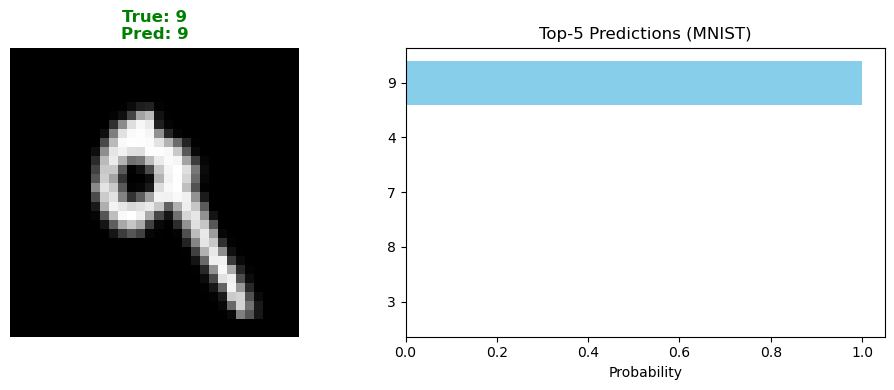


==================== Training VGG16 on CIFAR10 ====================
Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 1.3961
Epoch [2/10], Loss: 0.8838
Epoch [3/10], Loss: 0.6619
Epoch [4/10], Loss: 0.5229
Epoch [5/10], Loss: 0.4174
Epoch [6/10], Loss: 0.3373
Epoch [7/10], Loss: 0.2685
Epoch [8/10], Loss: 0.2225
Epoch [9/10], Loss: 0.1747
Epoch [10/10], Loss: 0.1487
Training finished in 241.07 seconds.
Metrics -> Acc: 0.8292 | Precision: 0.8311 | Recall: 0.8292 | F1: 0.8289


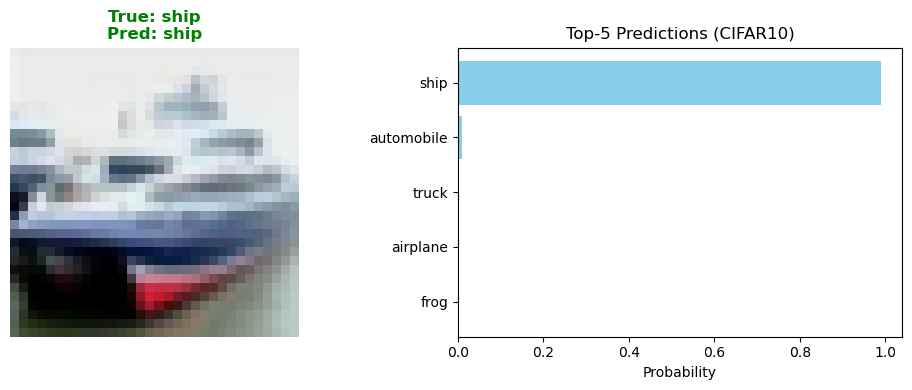


==================== Training VGG16 on CIFAR100 ====================
Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 4.2189
Epoch [2/10], Loss: 3.5744
Epoch [3/10], Loss: 3.1022
Epoch [4/10], Loss: 2.7019
Epoch [5/10], Loss: 2.3864
Epoch [6/10], Loss: 2.1220
Epoch [7/10], Loss: 1.8844
Epoch [8/10], Loss: 1.6893
Epoch [9/10], Loss: 1.5008
Epoch [10/10], Loss: 1.3189
Training finished in 239.22 seconds.
Metrics -> Acc: 0.4588 | Precision: 0.5105 | Recall: 0.4588 | F1: 0.4536


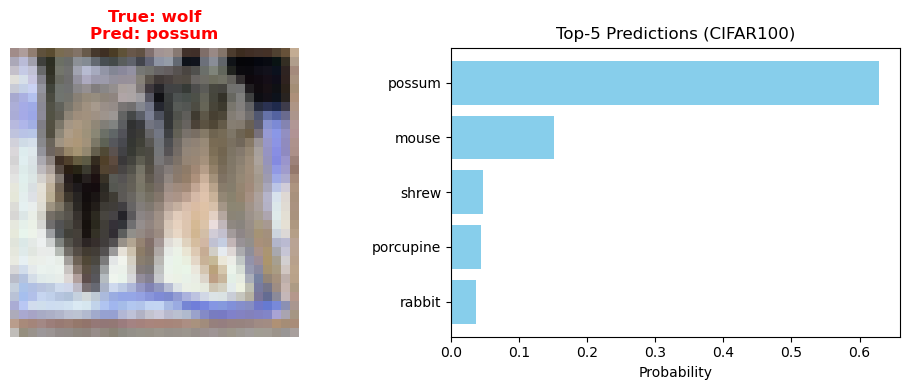

In [5]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ---------------------------------------------------------
# Device and Seed Configuration
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---------------------------------------------------------
# Training and Evaluation Function
# ---------------------------------------------------------
def train_and_evaluate(
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    epochs: int = 10,
    lr: float = 0.01
) -> Dict:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    train_loss_history = []
    
    print(f"Starting training for {epochs} epochs on {device}...")
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        train_loss_history.append(epoch_loss)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")
        
    total_training_time = time.time() - start_time
    print(f"Training finished in {total_training_time:.2f} seconds.")
    
    # Evaluation phase
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.numpy())
            
    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='macro', zero_division=0
    )
    
    metrics = {
        "training_time": total_training_time,
        "train_loss_history": train_loss_history,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }
    print(f"Metrics -> Acc: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    return metrics

# ---------------------------------------------------------
# VGG-16 Architecture from Scratch
# ---------------------------------------------------------
VGG16_CONFIG = [
    64, 64, 'M',
    128, 128, 'M',
    256, 256, 256, 'M',
    512, 512, 512, 'M',
    512, 512, 512, 'M'
]

class VGG16FromScratch(nn.Module):
    def __init__(self, in_channels: int = 3, num_classes: int = 10):
        super(VGG16FromScratch, self).__init__()
        self.in_channels = in_channels
        self.features = self._make_layers(VGG16_CONFIG)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Linear(512 * 1 * 1, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes)
        )
        
    def _make_layers(self, cfg: list) -> nn.Sequential:
        layers = []
        in_c = self.in_channels
        for x in cfg:
            if x == 'M':
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                layers.append(nn.Conv2d(in_c, x, kernel_size=3, padding=1))
                layers.append(nn.BatchNorm2d(x))
                layers.append(nn.ReLU(inplace=True))
                in_c = x
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)

# ---------------------------------------------------------
# Data Loader Function
# ---------------------------------------------------------
def get_vgg_dataloaders(dataset_name: str, batch_size: int = 32):
    dataset_name = dataset_name.upper()
    if dataset_name == "MNIST":
        transform = transforms.Compose([
            transforms.Resize((32, 32)),
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
        train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 1, 10, tuple(str(i) for i in range(10))
        
    elif dataset_name == "CIFAR10":
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
        ])
        train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 3, 10, train_set.classes
        
    elif dataset_name == "CIFAR100":
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
        ])
        train_set = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
        in_channels, num_classes, classes = 3, 100, train_set.classes

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2)
    return train_loader, test_loader, in_channels, num_classes, classes

# ---------------------------------------------------------
# Visualization Helper
# ---------------------------------------------------------
def visualize_vgg_prediction(model, test_loader, classes, dataset_name):
    model.eval()
    dataiter = iter(test_loader)
    images, labels = next(dataiter)
    idx = random.randint(0, images.size(0) - 1)
    
    img_tensor = images[idx].unsqueeze(0).to(device)
    true_label = classes[labels[idx].item()]
    
    with torch.no_grad():
        probs = model.predict_proba(img_tensor).cpu().squeeze().numpy()
        
    top5_idx = probs.argsort()[-5:][::-1]
    top5_probs = probs[top5_idx]
    top5_labels = [classes[i] for i in top5_idx]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    img_disp = images[idx].cpu()
    
    if img_disp.shape[0] == 1:
        ax1.imshow(img_disp.squeeze(), cmap='gray')
    else:
        img_disp = img_disp.permute(1, 2, 0).numpy()
        img_disp = (img_disp * np.array([0.2470, 0.2435, 0.2616]) + np.array([0.4914, 0.4822, 0.4465])).clip(0, 1)
        ax1.imshow(img_disp)
        
    color = "green" if top5_labels[0] == true_label else "red"
    ax1.set_title(f"True: {true_label}\nPred: {top5_labels[0]}", color=color, fontweight='bold')
    ax1.axis('off')
    
    ax2.barh(range(5), top5_probs, align='center', color='skyblue')
    ax2.set_yticks(range(5))
    ax2.set_yticklabels(top5_labels)
    ax2.invert_yaxis()
    ax2.set_xlabel('Probability')
    ax2.set_title(f"Top-5 Predictions ({dataset_name})")
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# Main Execution Loop
# ---------------------------------------------------------
vgg_experiments = {}

for d_name in ["MNIST", "CIFAR10", "CIFAR100"]:
    print(f"\n==================== Training VGG16 on {d_name} ====================")
    train_loader, test_loader, in_channels, num_classes, classes = get_vgg_dataloaders(d_name, batch_size=32)
    
    model = VGG16FromScratch(in_channels=in_channels, num_classes=num_classes).to(device)
    results = train_and_evaluate(model, train_loader, test_loader, epochs=10, lr=0.01)
    vgg_experiments[d_name] = results
    
    visualize_vgg_prediction(model, test_loader, classes, d_name)

In [6]:
# ---------------------------------------------------------
# Step 2.1: Quick Ablation Study for Conv Layers & Filters
# ---------------------------------------------------------
train_loader, test_loader, in_c, n_classes, _ = get_vgg_dataloaders("CIFAR10", batch_size=32)

class SimpleCNN(nn.Module):
    def __init__(self, num_conv_layers=2, base_channels=32):
        super(SimpleCNN, self).__init__()
        layers = []
        c_in = 3
        c_out = base_channels
        for _ in range(num_conv_layers):
            layers.extend([
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2, 2)
            ])
            c_in = c_out
            c_out *= 2
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(c_in, 10)
        
    def forward(self, x):
        return self.fc(torch.flatten(self.pool(self.features(x)), 1))

# Compare Conv Layers: 2 Layers vs 4 Layers
print("--- Evaluating Conv Layers (CIFAR-10, 3 Epochs) ---")
m_2layer = SimpleCNN(num_conv_layers=2, base_channels=64).to(device)
train_and_evaluate(m_2layer, train_loader, test_loader, epochs=3, lr=0.01)

m_4layer = SimpleCNN(num_conv_layers=4, base_channels=64).to(device)
train_and_evaluate(m_4layer, train_loader, test_loader, epochs=3, lr=0.01)

# Compare Conv Filters: Base 32 vs Base 64
print("\n--- Evaluating Conv Filters (CIFAR-10, 3 Epochs) ---")
m_filters32 = SimpleCNN(num_conv_layers=3, base_channels=32).to(device)
train_and_evaluate(m_filters32, train_loader, test_loader, epochs=3, lr=0.01)

--- Evaluating Conv Layers (CIFAR-10, 3 Epochs) ---
Starting training for 3 epochs on cuda...
Epoch [1/3], Loss: 1.7710
Epoch [2/3], Loss: 1.5476
Epoch [3/3], Loss: 1.4668
Training finished in 39.25 seconds.
Metrics -> Acc: 0.4534 | Precision: 0.5078 | Recall: 0.4534 | F1: 0.4448
Starting training for 3 epochs on cuda...
Epoch [1/3], Loss: 1.2476
Epoch [2/3], Loss: 0.8734
Epoch [3/3], Loss: 0.7109
Training finished in 41.38 seconds.
Metrics -> Acc: 0.6782 | Precision: 0.7372 | Recall: 0.6782 | F1: 0.6657

--- Evaluating Conv Filters (CIFAR-10, 3 Epochs) ---
Starting training for 3 epochs on cuda...
Epoch [1/3], Loss: 1.5891
Epoch [2/3], Loss: 1.2960
Epoch [3/3], Loss: 1.1757
Training finished in 38.36 seconds.
Metrics -> Acc: 0.5847 | Precision: 0.6157 | Recall: 0.5847 | F1: 0.5801


{'training_time': 38.363242387771606,
 'train_loss_history': [1.589091171684265,
  1.2959770770645143,
  1.175655540084839],
 'accuracy': 0.5847,
 'precision': 0.6156689747085138,
 'recall': 0.5847000000000001,
 'f1_score': 0.5801050093479201}